# Dataset EDA — RetailRocket e-commerce behaviour

Goal of this notebook:
1. **Describe** the data: what each file and column means.
2. **Size**: how big the data is (rows, columns, disk, memory, unique entities, time span).
3. **Distribution**: how events, visitors, items, properties and categories are distributed.

| File | Columns |
|---|---|
| `events.csv` | `timestamp`, `visitorid`, `event` (view / addtocart / transaction), `itemid`, `transactionid` |
| `item_properties_part1.csv` + `part2.csv` | `timestamp`, `itemid`, `property`, `value` |
| `category_tree.csv` | `categoryid`, `parentid` |

Most property names and values are hashed. Only `categoryid` and `available` are readable.

## 1. Setup & load data

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from tqdm import tqdm

load_dotenv()
DATA_DIR = os.getenv("DATA_DIR", "../dataset")
sns.set_theme(style="whitegrid")

Matplotlib is building the font cache; this may take a moment.


In [2]:
events = pd.read_csv(f"{DATA_DIR}/events.csv")
category_tree = pd.read_csv(f"{DATA_DIR}/category_tree.csv")

parts = []
for name in tqdm(["item_properties_part1.csv", "item_properties_part2.csv"]):
    parts.append(pd.read_csv(f"{DATA_DIR}/{name}", dtype={"property": "category"}))
item_props = pd.concat(parts, ignore_index=True)
del parts

# timestamps are in milliseconds
events["datetime"] = pd.to_datetime(events["timestamp"], unit="ms")
item_props["datetime"] = pd.to_datetime(item_props["timestamp"], unit="ms")

100%|██████████| 2/2 [00:42<00:00, 21.41s/it]


## 2. Data description

In [3]:
events.head()

,timestamp,visitorid,event,itemid,transactionid,datetime
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106


In [4]:
item_props.head()

,timestamp,itemid,property,value,datetime
0,1435460400000,460429,categoryid,1338,2015-06-28 03:00:00
1,1441508400000,206783,888,1116713 960601 n277.200,2015-09-06 03:00:00
2,1439089200000,395014,400,n552.000 639502 n720.000 424566,2015-08-09 03:00:00
3,1431226800000,59481,790,n15360.000,2015-05-10 03:00:00
4,1431831600000,156781,917,828513,2015-05-17 03:00:00


In [5]:
category_tree.head()

,categoryid,parentid
0,1016,213.0
1,809,169.0
2,570,9.0
3,1691,885.0
4,536,1691.0


In [6]:
events.info()
print()
item_props.info()
print()
category_tree.info()

<class 'pandas.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 6 columns):
 #   Column         Dtype         
---  ------         -----         
 0   timestamp      int64         
 1   visitorid      int64         
 2   event          str           
 3   itemid         int64         
 4   transactionid  float64       
 5   datetime       datetime64[ms]
dtypes: datetime64[ms](1), float64(1), int64(3), str(1)
memory usage: 126.2 MB

<class 'pandas.DataFrame'>
RangeIndex: 20275902 entries, 0 to 20275901
Data columns (total 5 columns):
 #   Column     Dtype         
---  ------     -----         
 0   timestamp  int64         
 1   itemid     int64         
 2   property   str           
 3   value      str           
 4   datetime   datetime64[ms]
dtypes: datetime64[ms](1), int64(2), str(2)
memory usage: 773.5 MB

<class 'pandas.DataFrame'>
RangeIndex: 1669 entries, 0 to 1668
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------    

In [8]:
events.describe()

,timestamp,visitorid,itemid,transactionid,datetime
count,2.756101e+06,2.756101e+06,2.756101e+06,22457.000000,2756101
mean,1.436424e+12,7.019229e+05,2.349225e+05,8826.497796,2015-07-09 06:48:08.348000
min,1.430622e+12,0.000000e+00,3.000000e+00,0.000000,2015-05-03 03:00:04.384000
25%,1.433478e+12,3.505660e+05,1.181200e+05,4411.000000,2015-06-05 04:23:14.792000
50%,1.436453e+12,7.020600e+05,2.360670e+05,8813.000000,2015-07-09 14:43:33.599000
75%,1.439225e+12,1.053437e+06,3.507150e+05,13224.000000,2015-08-10 16:45:05.168000
max,1.442545e+12,1.407579e+06,4.668670e+05,17671.000000,2015-09-18 02:59:47.788000
std,3.366312e+09,4.056875e+05,1.341954e+05,5098.996290,NaN


In [9]:
# missing values per column
print(events.isna().sum(), "\n")
print(item_props.isna().sum(), "\n")
print(category_tree.isna().sum())

timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
datetime               0
dtype: int64 

timestamp    0
itemid       0
property     0
value        0
datetime     0
dtype: int64 

categoryid     0
parentid      25
dtype: int64


In [10]:
print("Duplicate rows in events:", events.duplicated().sum())

Duplicate rows in events: 460


**Key takeaways: data description**
- `events` has 2.76M rows with no missing values, except `transactionid`. That one is empty by design: it is only filled for `transaction` events (2,756,101 − 2,733,644 = 22,457 transactions).
- `item_props` has no missing values, but almost every `property` and `value` is hashed. Only `categoryid` and `available` can be interpreted.
- `category_tree` has 25 missing `parentid`. These are the 25 **root categories**, not bad data.
- `events` has 460 duplicate rows (0.02%). They are small enough to simply drop.

## 3. How big is the data?

In [11]:
for name, df in {"events": events, "item_props": item_props, "category_tree": category_tree}.items():
    mem_mb = df.memory_usage(deep=True).sum() / 1024**2
    print(f"{name:14} rows={len(df):>11,}  cols={df.shape[1]}  memory={mem_mb:,.0f} MB")

events         rows=  2,756,101  cols=6  memory=266 MB
item_props     rows= 20,275,902  cols=5  memory=3,080 MB
category_tree  rows=      1,669  cols=2  memory=0 MB


In [12]:
print("Unique visitors:     ", events["visitorid"].nunique())
print("Unique items (events):", events["itemid"].nunique())
print("Unique transactions: ", events["transactionid"].nunique())
print("Events period:       ", events["datetime"].min(), "->", events["datetime"].max())
print()
print("Unique items (props): ", item_props["itemid"].nunique())
print("Unique properties:   ", item_props["property"].nunique())
print("Props period:        ", item_props["datetime"].min(), "->", item_props["datetime"].max())
print()
print("Categories:          ", category_tree["categoryid"].nunique())
print("Root categories:     ", category_tree["parentid"].isna().sum())

Unique visitors:      1407580
Unique items (events): 235061
Unique transactions:  17672
Events period:        2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000

Unique items (props):  417053
Unique properties:    1104
Props period:         2015-05-10 03:00:00 -> 2015-09-13 03:00:00

Categories:           1669
Root categories:      25


**Key takeaways: data size**
- `item_props` is the heavy table: 20.3M rows, about 3 GB in memory, mostly from the `value` strings. `events` is about 0.27 GB and `category_tree` is tiny.
- 1.4M visitors, 235K items and 17.7K transactions over about 4.5 months (2015-05-03 to 2015-09-18).
- `item_props` covers 417K items, but only 235K items appear in `events`, so many catalogue items were never interacted with.
- 1,104 distinct properties, recorded as weekly snapshots (2015-05-10 to 2015-09-13).

## 4. Distribution of the data

### 4.1 Event types

event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


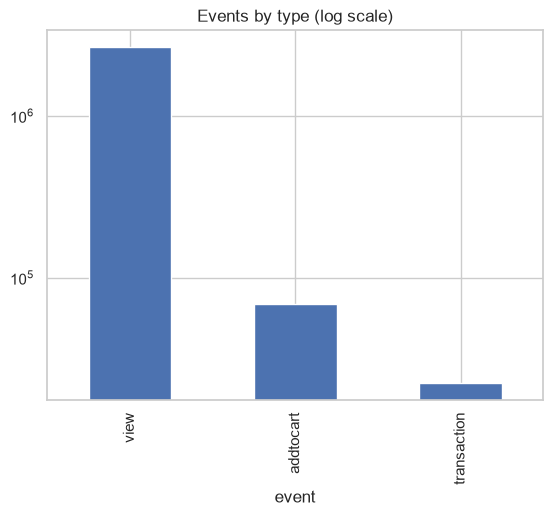

In [16]:
event_counts = events["event"].value_counts()
print(event_counts)

event_counts.plot(kind="bar", logy=True, title="Events by type (log scale)")
plt.show()

**Key takeaways: event types**
- Views dominate: 2.66M views (96.7%) vs 69K add-to-carts (2.5%) and 22K transactions (0.8%).
- Only about 2.6% of views lead to an add-to-cart, but about 32% of add-to-carts lead to a transaction.
- The classes are heavily imbalanced, which matters for any purchase-prediction model.

### 4.2 Events over time

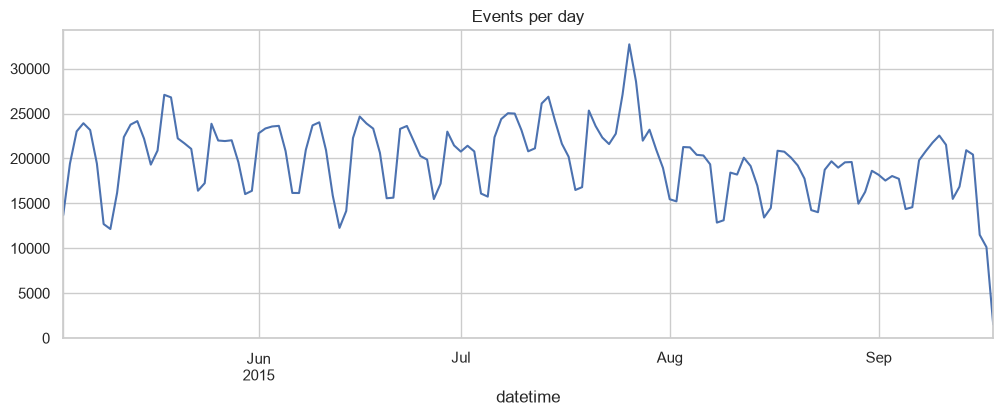

In [19]:
events.set_index("datetime").resample("D").size().plot(figsize=(12, 4), title="Events per day")
plt.show()

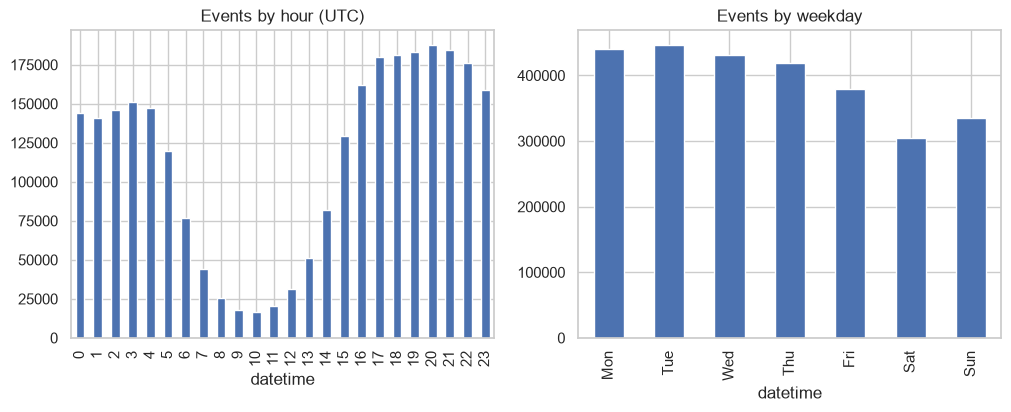

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
events["datetime"].dt.hour.value_counts().sort_index().plot(kind="bar", ax=axes[0], title="Events by hour (UTC)")
weekdays = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
events["datetime"].dt.day_name().str[:3].value_counts().reindex(weekdays).plot(kind="bar", ax=axes[1], title="Events by weekday")
plt.show()

**Key takeaways: events over time**
- Traffic is stable at about 15K–25K events per day with a clear **weekly cycle**. There is a one-off spike of about 33K in late July.
- The first and last days are low only because they are partial days. The data starts and ends around 03:00 UTC.
- By hour (UTC), activity is lowest at 08:00–11:00 and highest at 17:00–21:00. That pattern fits users in the Americas, so local time is likely several hours behind UTC.
- Weekdays are busier than weekends. Monday and Tuesday are the peak and Saturday is the quietest.

### 4.3 Events per visitor and per item

In [28]:
events_per_visitor = events.groupby("visitorid").size()
events_per_item = events.groupby("itemid").size()

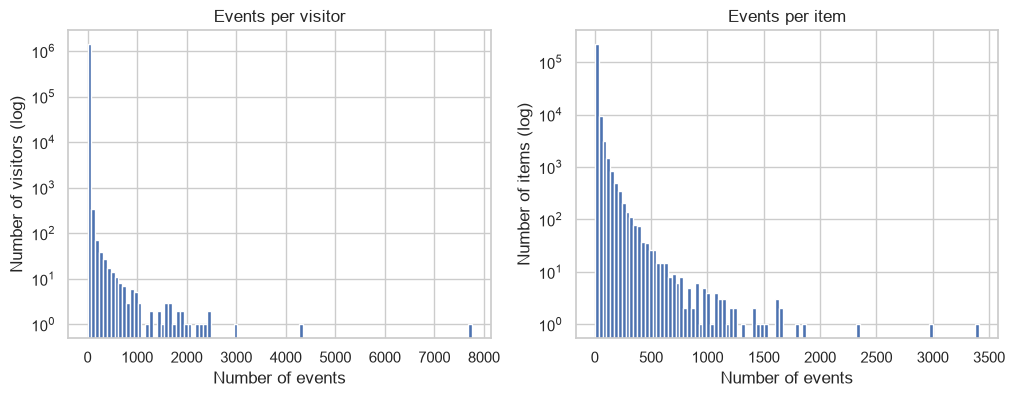

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(events_per_visitor, bins=100, log=True)
axes[0].set_title("Events per visitor")
axes[0].set_xlabel("Number of events")
axes[0].set_ylabel("Number of visitors (log)")
axes[1].hist(events_per_item, bins=100, log=True)
axes[1].set_title("Events per item")
axes[1].set_xlabel("Number of events")
axes[1].set_ylabel("Number of items (log)")
plt.show()

**Key takeaways: events per visitor and per item**
- Both are extremely **long-tailed**. Almost every visitor has only a handful of events, and most items get very few interactions.
- A few visitors have thousands of events (up to about 7,700). That is unrealistic for a human, so they are likely bots or crawlers and should be checked or filtered.
- A small set of items receives up to about 3,400 events each. Popularity is concentrated on a few products.

### 4.4 Transactions

count    17672.000000
mean         1.270767
std          0.974793
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         31.000000
dtype: float64


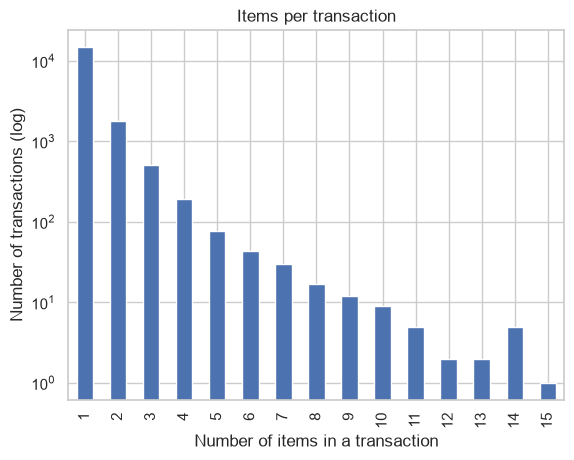

In [32]:
items_per_transaction = events.groupby("transactionid").size()
print(items_per_transaction.describe())

ax = items_per_transaction.value_counts().sort_index().head(15).plot(kind="bar", logy=True, title="Items per transaction")
ax.set_xlabel("Number of items in a transaction")
ax.set_ylabel("Number of transactions (log)")
plt.show()

**Key takeaways: transactions**
- Most transactions contain just **one item**: median 1, mean 1.27, and about 15K of 17.7K transactions.
- Multi-item baskets are rare and drop off quickly. The largest has 31 items.

### 4.5 Item properties

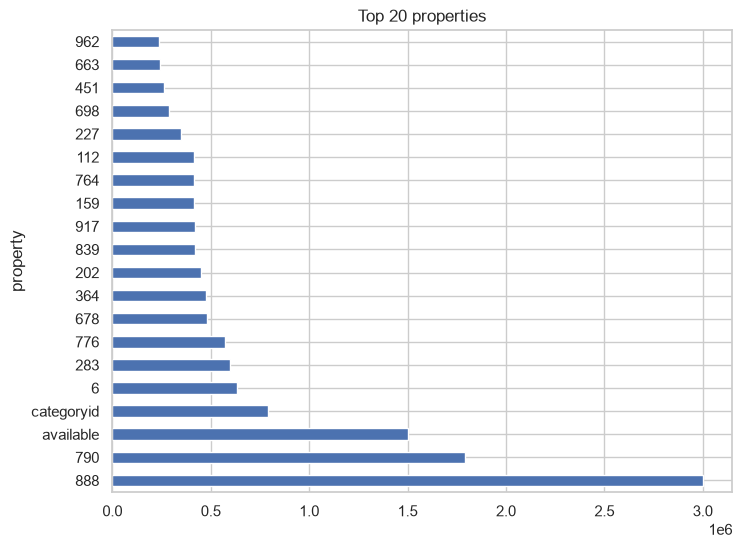

In [33]:
item_props["property"].value_counts().head(20).plot(kind="barh", figsize=(8, 6), title="Top 20 properties")
plt.show()

count     1180.000000
mean       353.434746
std        997.459967
min          1.000000
25%         14.000000
50%         78.500000
75%        289.250000
max      17231.000000
Name: count, dtype: float64


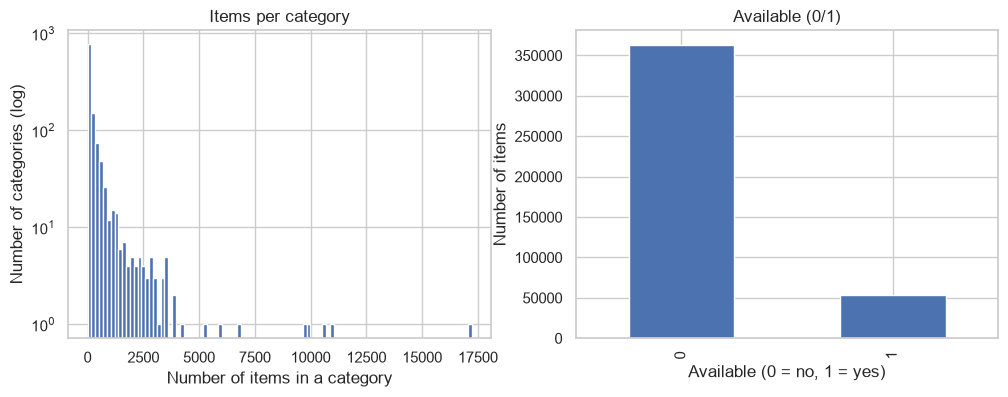

In [36]:
# items per category and availability (latest value per item)
readable = item_props[item_props["property"].isin(["categoryid", "available"])]
latest = readable.sort_values("timestamp").drop_duplicates(["itemid", "property"], keep="last")

items_per_category = latest[latest["property"] == "categoryid"]["value"].value_counts()
print(items_per_category.describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(items_per_category, bins=100, log=True)
axes[0].set_title("Items per category")
axes[0].set_xlabel("Number of items in a category")
axes[0].set_ylabel("Number of categories (log)")
latest[latest["property"] == "available"]["value"].value_counts().plot(kind="bar", ax=axes[1], title="Available (0/1)")
axes[1].set_xlabel("Available (0 = no, 1 = yes)")
axes[1].set_ylabel("Number of items")
plt.show()

**Key takeaways: item properties**
- Property `888` has the most rows (about 3M), followed by `790` (about 1.8M), `available` (about 1.5M) and `categoryid` (about 0.8M). The many `available` rows suggest stock status changes often.
- Items map to 1,180 of the 1,669 categories. Category size is very skewed: the median is about 79 items, while the largest category has 17K items.
- In the latest snapshot, about 87% of items are **unavailable** (about 362K vs 53K available). This is the latest state only. An item may have been available when it was viewed.

## 5. Overall summary
- **Behaviour:** browsing dominates. Fewer than 1% of events are purchases, but once an item is in the cart, about 1 in 3 is bought.
- **Skew everywhere:** visitors, items, categories and basket sizes all have long tails. Use medians or log scales, not means.
- **Data cleaning needed:** drop the 460 duplicate events, and check the extreme visitors (likely bots).
- **Time patterns:** strong daily and weekly cycles (weekday afternoons and evenings UTC are busiest). These are useful features for modelling.
- **Item properties:** large and mostly hashed. Only `categoryid` and `available` are directly useful, and they change over time, so join them by timestamp, not just by item.